# Pricing and validation

The implied smile, its density, the Dupire local volatility built from it, and the Monte Carlo engine checked against closed forms, every comparison in standard errors.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
BLUE, GREEN, RED, ORANGE, GREY = "#1f4e79", "#1a9850", "#d73027", "#f46d43", "#7f7f7f"

arbitrage-free: True


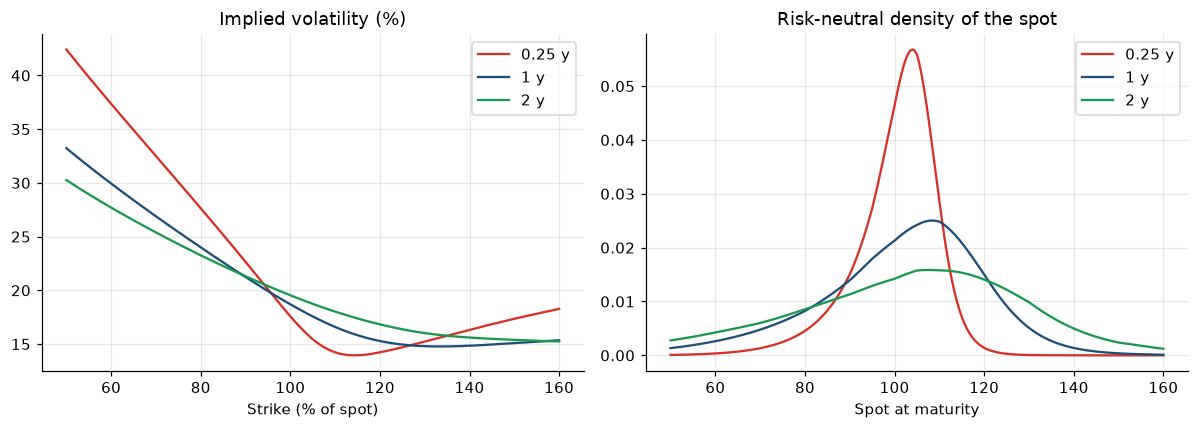

In [2]:
from spricer.bricks import DigitalOption, EuropeanOption
from spricer.market.defaults import default_market
from spricer.mc import local_vol, simulate

market = default_market()
surface = market.vol
strikes = np.linspace(50, 160, 221)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
for t, color in zip((0.25, 1.0, 2.0), (RED, BLUE, GREEN), strict=True):
    left.plot(strikes, 100 * surface.vol(strikes, t), color=color, label=f"{t:g} y")
    right.plot(strikes, surface.density(strikes, t), color=color, label=f"{t:g} y")
left.set(title="Implied volatility (%)", xlabel="Strike (% of spot)")
right.set(title="Risk-neutral density of the spot", xlabel="Spot at maturity")
left.legend()
right.legend()
fig.tight_layout()
print("arbitrage-free:", surface.check_arbitrage().is_arbitrage_free)

## Local volatility

The diffusion coefficient that reprices every European option of the surface (Dupire, in total variance). The short end is steep: the skew of short-dated options must come from a strongly spot-dependent volatility.

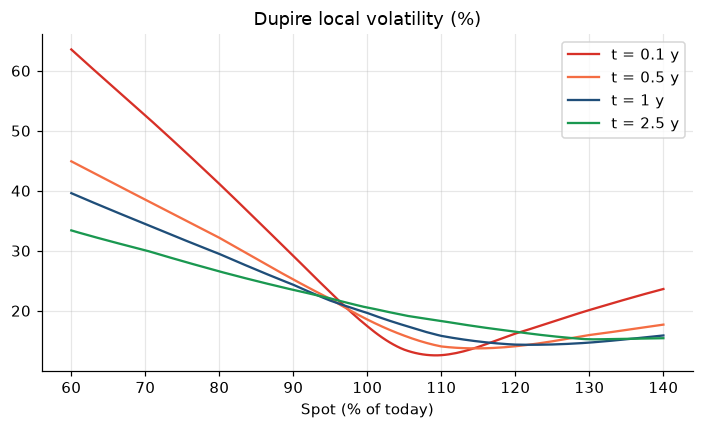

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4))
spots = np.linspace(60, 140, 161)
for t, color in zip((0.1, 0.5, 1.0, 2.5), (RED, ORANGE, BLUE, GREEN), strict=True):
    ax.plot(spots, 100 * local_vol(market, spots, t), color=color, label=f"t = {t:g} y")
ax.set(title="Dupire local volatility (%)", xlabel="Spot (% of today)")
ax.legend()
fig.tight_layout()

## The Monte Carlo reprices the smile

200,000 paths (100,000 antithetic pairs), weekly steps graded from daily near today, Richardson extrapolation.

In [4]:
times = [0.5, 2.0, 5.0]
paths = simulate(market, times, n_paths=200_000, seed=11)
worst = 0.0
print(f"{'maturity':>8} {'instrument':>22} {'exact':>9} {'MC':>9} {'± s.e.':>8} {'z':>6}")
for t in times:
    s, df = paths.spot_at(t), paths.discount(t)
    for k in (70.0, 100.0, 130.0):
        kind = "put" if k < 100 else "call"
        for brick in (EuropeanOption(kind, k, t), DigitalOption("call", k, t)):
            est = paths.estimate(brick.payoff(s) * df)
            exact = float(brick.value(market))
            z = (est.value - exact) / est.std_error
            worst = max(worst, abs(z))
            print(
                f"{t:>8g} {brick.label:>22} {exact:9.4f} {est.value:9.4f} "
                f"{est.std_error:8.4f} {z:+6.1f}"
            )
print(f"largest gap: {worst:.1f} standard errors")

maturity             instrument     exact        MC   ± s.e.      z
     0.5          Put K=70 0.5y    0.2732    0.2676   0.0047   -1.2
     0.5 Digital call K=70 0.5y    0.9554    0.9563   0.0004   +2.0
     0.5        Call K=100 0.5y    5.2676    5.2569   0.0092   -1.2
     0.5 Digital call K=100 0.5y    0.5772    0.5779   0.0007   +1.0
     0.5        Call K=130 0.5y    0.0227    0.0231   0.0011   +0.4
     0.5 Digital call K=130 0.5y    0.0045    0.0045   0.0002   -0.2
       2            Put K=70 2y    2.1444    2.1394   0.0156   -0.3
       2   Digital call K=70 2y    0.8171    0.8172   0.0007   +0.0
       2          Call K=100 2y   11.4323   11.4267   0.0224   -0.2
       2  Digital call K=100 2y    0.5345    0.5346   0.0006   +0.2
       2          Call K=130 2y    1.7819    1.7774   0.0137   -0.3
       2  Digital call K=130 2y    0.1319    0.1315   0.0007   -0.6
       5            Put K=70 5y    5.0030    5.0046   0.0235   +0.1
       5   Digital call K=70 5y    0.6593    0

## Richardson extrapolation removes the Euler bias

A six-month at-the-money digital is the most sensitive case: 400,000 paths, five seeds.

     Euler: bias -27.3 bp of the digital ± 1.8 bp (-14.9 standard errors)
Richardson: bias +3.5 bp of the digital ± 2.3 bp (+1.5 standard errors)


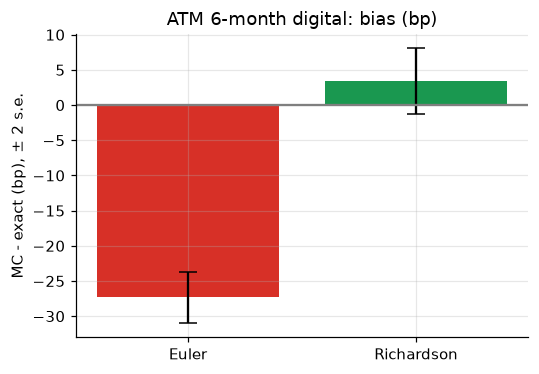

In [5]:
digital = DigitalOption("call", 100.0, 0.5)
exact = float(digital.value(market))
rows = {}
for rich in (False, True):
    est = [simulate(market, [0.5], n_paths=400_000, seed=s, richardson=rich) for s in range(5)]
    values = [p.estimate(digital.payoff(p.spot_at(0.5)) * p.discount(0.5)) for p in est]
    mean = np.mean([v.value for v in values])
    error = math.sqrt(sum(v.std_error**2 for v in values)) / len(values)
    rows["Richardson" if rich else "Euler"] = (mean - exact, error)
for name, (bias, error) in rows.items():
    print(
        f"{name:>10}: bias {1e4 * bias:+.1f} bp of the digital ± {1e4 * error:.1f} bp "
        f"({bias / error:+.1f} standard errors)"
    )
fig, ax = plt.subplots(figsize=(5, 3.5))
names = list(rows)
ax.bar(
    names,
    [1e4 * rows[n][0] for n in names],
    yerr=[2 * 1e4 * rows[n][1] for n in names],
    color=[RED, GREEN],
    capsize=6,
)
ax.axhline(0, color=GREY)
ax.set(title="ATM 6-month digital: bias (bp)", ylabel="MC - exact (bp), ± 2 s.e.")
fig.tight_layout()